In [1]:
#Inventory Optimization

import pandas as pd 
import numpy as np 
import  matplotlib.pyplot as plt 
import seaborn as sns

In [2]:
df = pd.read_csv("cleaned_retail.csv")
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice,RollingAvgSales
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,NaN
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,NaN
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,NaN
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,NaN
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,19.664


In [4]:
daily_demand = (
    df.groupby(["Description", df["InvoiceDate"].dt.date])
    ["Quantity"].sum().reset_index()
)

daily_demand.head()

,Description,InvoiceDate,Quantity
0,4 PURPLE FLOCK DINNER CANDLES,2010-12-01,2
1,4 PURPLE FLOCK DINNER CANDLES,2010-12-05,12
2,4 PURPLE FLOCK DINNER CANDLES,2011-01-05,1
3,4 PURPLE FLOCK DINNER CANDLES,2011-01-26,1
4,4 PURPLE FLOCK DINNER CANDLES,2011-02-28,1


In [6]:
avg_demand = (
    daily_demand.groupby("Description")["Quantity"].mean() .reset_index())

avg_demand.rename(columns={"Quantity":"AverageDailyDemand"},inplace=True)
avg_demand.head()

,Description,AverageDailyDemand
0,4 PURPLE FLOCK DINNER CANDLES,4.312500
1,50'S CHRISTMAS GIFT BAG LARGE,31.416667
2,DOLLY GIRL BEAKER,28.843373
3,I LOVE LONDON MINI BACKPACK,8.159091
4,I LOVE LONDON MINI RUCKSACK,1.000000


In [7]:
max_demand = (daily_demand.groupby("Description")["Quantity"].max().reset_index())

max_demand.rename(columns={"Quantity":"MaximumDailyDemand"},inplace=True)
max_demand.head()

,Description,MaximumDailyDemand
0,4 PURPLE FLOCK DINNER CANDLES,24
1,50'S CHRISTMAS GIFT BAG LARGE,436
2,DOLLY GIRL BEAKER,407
3,I LOVE LONDON MINI BACKPACK,52
4,I LOVE LONDON MINI RUCKSACK,1


In [8]:
inventory = pd.merge(avg_demand, max_demand,on="Description")
inventory.head()

,Description,AverageDailyDemand,MaximumDailyDemand
0,4 PURPLE FLOCK DINNER CANDLES,4.312500,24
1,50'S CHRISTMAS GIFT BAG LARGE,31.416667,436
2,DOLLY GIRL BEAKER,28.843373,407
3,I LOVE LONDON MINI BACKPACK,8.159091,52
4,I LOVE LONDON MINI RUCKSACK,1.000000,1


In [10]:
inventory["SafetyStock"] = (inventory["MaximumDailyDemand"]- inventory["AverageDailyDemand"]) * lead_time
inventory.head()

,Description,AverageDailyDemand,MaximumDailyDemand,SafetyStock
0,4 PURPLE FLOCK DINNER CANDLES,4.312500,24,137.812500
1,50'S CHRISTMAS GIFT BAG LARGE,31.416667,436,2832.083333
2,DOLLY GIRL BEAKER,28.843373,407,2647.096386
3,I LOVE LONDON MINI BACKPACK,8.159091,52,306.886364
4,I LOVE LONDON MINI RUCKSACK,1.000000,1,0.000000


In [11]:
inventory["ReorderPoint"] = (inventory["AverageDailyDemand"] * lead_time) + inventory["SafetyStock"]
inventory.head()

,Description,AverageDailyDemand,MaximumDailyDemand,SafetyStock,ReorderPoint
0,4 PURPLE FLOCK DINNER CANDLES,4.312500,24,137.812500,168.0
1,50'S CHRISTMAS GIFT BAG LARGE,31.416667,436,2832.083333,3052.0
2,DOLLY GIRL BEAKER,28.843373,407,2647.096386,2849.0
3,I LOVE LONDON MINI BACKPACK,8.159091,52,306.886364,364.0
4,I LOVE LONDON MINI RUCKSACK,1.000000,1,0.000000,7.0


In [12]:
inventory["Category"] = np.where(
    inventory["AverageDailyDemand"] > inventory["AverageDailyDemand"].median(),
    "Fast Moving",
    "Slow Moving"
)

inventory.head()

,Description,AverageDailyDemand,MaximumDailyDemand,SafetyStock,ReorderPoint,Category
0,4 PURPLE FLOCK DINNER CANDLES,4.312500,24,137.812500,168.0,Slow Moving
1,50'S CHRISTMAS GIFT BAG LARGE,31.416667,436,2832.083333,3052.0,Fast Moving
2,DOLLY GIRL BEAKER,28.843373,407,2647.096386,2849.0,Fast Moving
3,I LOVE LONDON MINI BACKPACK,8.159091,52,306.886364,364.0,Slow Moving
4,I LOVE LONDON MINI RUCKSACK,1.000000,1,0.000000,7.0,Slow Moving


In [13]:
top_products = (
    inventory.sort_values(
        by="AverageDailyDemand",
        ascending=False
    )
    .head(10)
)

top_products

,Description,AverageDailyDemand,MaximumDailyDemand,SafetyStock,ReorderPoint,Category
2319,"PAPER CRAFT , LITTLE BIRDIE",80995.000000,80995,0.000000,566965.0,Fast Moving
3423,TEA TIME TEA TOWELS,1300.000000,1300,0.000000,9100.0,Fast Moving
1992,MEDIUM CERAMIC TOP STORAGE JAR,677.530435,74215,514762.286957,519505.0,Fast Moving
1398,GIRLS ALPHABET IRON ON PATCHES,501.818182,1728,8583.272727,12096.0,Fast Moving
1155,ESSENTIAL BALM 3.5g TIN IN ENVELOPE,418.285714,3206,19514.000000,22442.0,Fast Moving
2656,RABBIT NIGHT LIGHT,288.861702,2647,16506.968085,18529.0,Fast Moving
3135,SET/5 RED SPOTTY LID GLASS BOWLS,288.000000,288,0.000000,2016.0,Fast Moving
3242,SMALL CHINESE STYLE SCISSOR,272.000000,3020,19236.000000,21140.0,Fast Moving
531,BOYS ALPHABET IRON ON PATCHES,249.600000,288,268.800000,2016.0,Fast Moving
3786,WORLD WAR 2 GLIDERS ASSTD DESIGNS,241.417778,4848,32246.075556,33936.0,Fast Moving


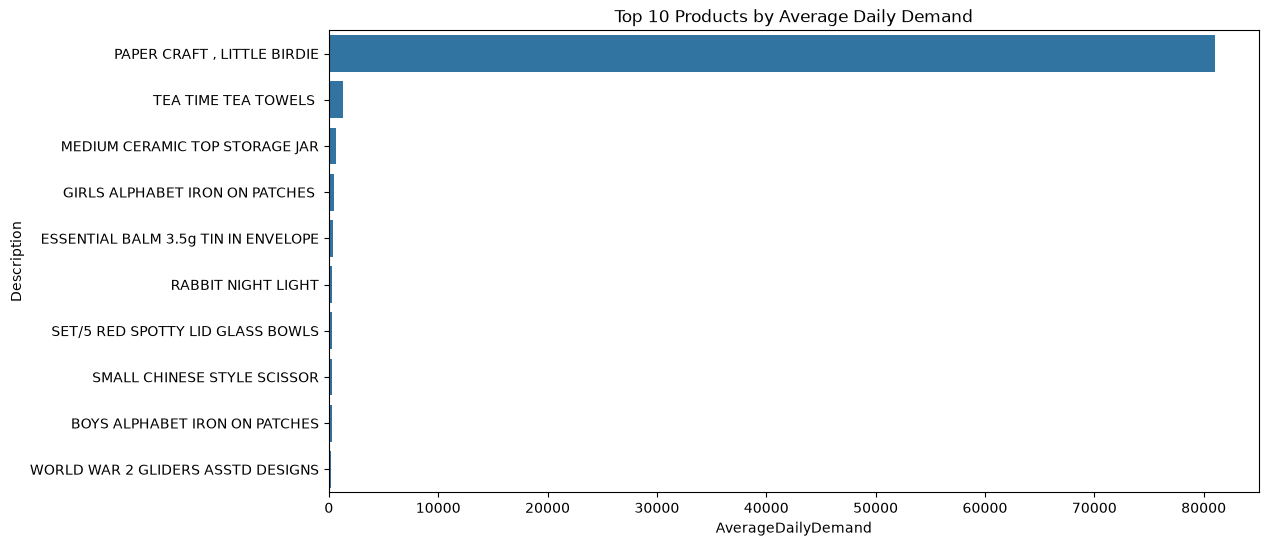

In [14]:
plt.figure(figsize=(12,6))

sns.barplot(
    data=top_products,
    x="AverageDailyDemand",
    y="Description"
)

plt.title("Top 10 Products by Average Daily Demand")

plt.show()

In [15]:
inventory["Category"].value_counts()

Category
Slow Moving    1939
Fast Moving    1938
Name: count, dtype: int64

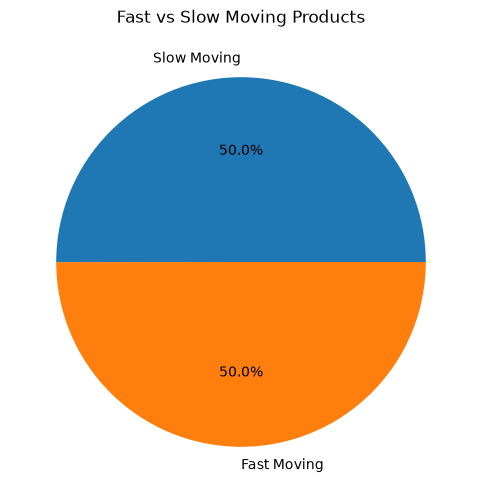

In [16]:
plt.figure(figsize=(6,6))

inventory["Category"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%"
)

plt.ylabel("")

plt.title("Fast vs Slow Moving Products")

plt.show()

In [17]:
inventory.to_csv(
    "inventory_report.csv",
    index=False
)

print("Inventory report saved successfully.")

Inventory report saved successfully.
